# بخش 7: تحلیل معماری دوطرفه (Bidirectional) در پیش‌بینی سری‌های زمانی

In [4]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt


from data_utils import get_dataloaders
from plotting import save_figure, save_table



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
data_path = None
batch_size = 64
hidden_size = 32
seq_length = 20
epochs = 50
learning_rate = 0.01



در این بخش، معماری‌های بازگشتی دوطرفه (Bidirectional) را با همتایان یک‌طرفه خود مقایسه می‌کنیم. در معماری دوطرفه، اطلاعات از هر دو جهت (گذشته و آینده) پردازش می‌شود که در بسیاری از کاربردهای NLP  مؤثر است، اما در پیش‌بینی سری‌های زمانی (به دلیل دسترسی نداشتن به آینده در زمان پیش‌بینی) ممکن است نامناسب باشد. هدف این آزمایش، ارزیابی عملکرد و محدودیت‌های این معماری در مسئله پیش‌بینی گام بعد است.

 ## معماری پایه

یک مدل LSTM یک‌طرفه (Unidirectional) و یک مدل LSTM دوطرفه (Bidirectional) با همان تعداد پارامتر (حداقل تعداد لایه‌ها و اندازه نهان یکسان) طراحی کنید. سایر تنظیمات به‌صورت زیر ثابت هستند:

•	تعداد لایه‌ها: ۱

•	اندازه نهان: ۳۲

•	طول پنجره ورودی: ۲۰

•	تابع هزینه: MSE

•	بهینه‌ساز: Adam با نرخ یادگیری ۰.۰۱

•	تعداد دوره‌ها: ۵۰


7-1- برای هر دو مدل (یک‌طرفه و دوطرفه)، جدول زیر را کامل کنید:

o	تعداد پارامترهای قابل آموزش

o	MSE  روی مجموعه آزمون

o	زمان آموزش (ثانیه)


In [8]:
train_loader, test_loader, _ = get_dataloaders(
    seq_length=seq_length, batch_size=batch_size, data_path=data_path
)


In [5]:
class UniLSTM(nn.Module):
    """Unidirectional LSTM."""
    def __init__(self, input_size=5, hidden_size=32, output_size=1):
        super(UniLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True, bidirectional=False)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return self.fc(out).squeeze(-1)

class BiLSTM(nn.Module):
    """Bidirectional LSTM."""
    def __init__(self, input_size=5, hidden_size=32, output_size=1):
        super(BiLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size * 2, output_size)  # Concatenated forward + backward

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # Last time step: shape (batch, hidden_size*2)
        return self.fc(out).squeeze(-1)


In [6]:
def train_and_evaluate(model, train_loader, test_loader, epochs=50, lr=0.01, verbose=True):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_train_loss = epoch_loss / len(train_loader)

        # Evaluation
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                test_loss += loss.item()
        avg_test_loss = test_loss / len(test_loader)

        if verbose and (epoch + 1) % 10 == 0:
            print(f"{model.__class__.__name__:8s} Epoch {epoch+1:2d}/{epochs} | Train Loss: {avg_train_loss:.6f} | Test Loss: {avg_test_loss:.6f}")

    training_time = time.time() - start_time
    final_test_loss = avg_test_loss

    # Compute MAE for extra info
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            preds = model(X_batch)
            all_preds.append(preds.cpu().numpy())
            all_targets.append(y_batch.cpu().numpy())
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    mae = np.mean(np.abs(all_preds - all_targets))

    return final_test_loss, mae, training_time

def get_model_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [9]:

# UniLSTM
print("\n--- Training Unidirectional LSTM ---")
model_uni = UniLSTM(input_size=5, hidden_size=hidden_size)
params_uni = get_model_params(model_uni)
mse_uni, mae_uni, time_uni = train_and_evaluate(model_uni, train_loader, test_loader, epochs, learning_rate)



--- Training Unidirectional LSTM ---
UniLSTM  Epoch 10/50 | Train Loss: 0.397734 | Test Loss: 0.394842
UniLSTM  Epoch 20/50 | Train Loss: 0.397007 | Test Loss: 0.395323
UniLSTM  Epoch 30/50 | Train Loss: 0.397233 | Test Loss: 0.394932
UniLSTM  Epoch 40/50 | Train Loss: 0.395606 | Test Loss: 0.393615
UniLSTM  Epoch 50/50 | Train Loss: 0.395483 | Test Loss: 0.397117


In [10]:
print("\n--- Training Bidirectional LSTM ---")
model_bi = BiLSTM(input_size=5, hidden_size=hidden_size)
params_bi = get_model_params(model_bi)
mse_bi, mae_bi, time_bi = train_and_evaluate(model_bi, train_loader, test_loader, epochs, learning_rate)



--- Training Bidirectional LSTM ---
BiLSTM   Epoch 10/50 | Train Loss: 0.398201 | Test Loss: 0.394922
BiLSTM   Epoch 20/50 | Train Loss: 0.397855 | Test Loss: 0.404988
BiLSTM   Epoch 30/50 | Train Loss: 0.396796 | Test Loss: 0.395567
BiLSTM   Epoch 40/50 | Train Loss: 0.397581 | Test Loss: 0.456630
BiLSTM   Epoch 50/50 | Train Loss: 0.400624 | Test Loss: 0.408077


In [11]:
results = pd.DataFrame({
    'Model': ['Unidirectional LSTM', 'Bidirectional LSTM'],
    'Parameters': [params_uni, params_bi],
    'MSE (Test)': [mse_uni, mse_bi],
    'MAE (Test)': [mae_uni, mae_bi],
    'Training Time (s)': [time_uni, time_bi]
})
print("\n" + "="*70)
print("COMPARISON RESULTS")
print("="*70)
print(results.to_string(index=False))
save_table(results, 'bidirectional_comparison')



COMPARISON RESULTS
              Model  Parameters  MSE (Test)  MAE (Test)  Training Time (s)
Unidirectional LSTM        5025    0.397117    0.503674          73.489168
 Bidirectional LSTM       10049    0.408077    0.510088          84.049268


,Model,Parameters,MSE (Test),MAE (Test),Training Time (s)
0,Unidirectional LSTM,5025,0.397117,0.503674,73.489168
1,Bidirectional LSTM,10049,0.408077,0.510088,84.049268


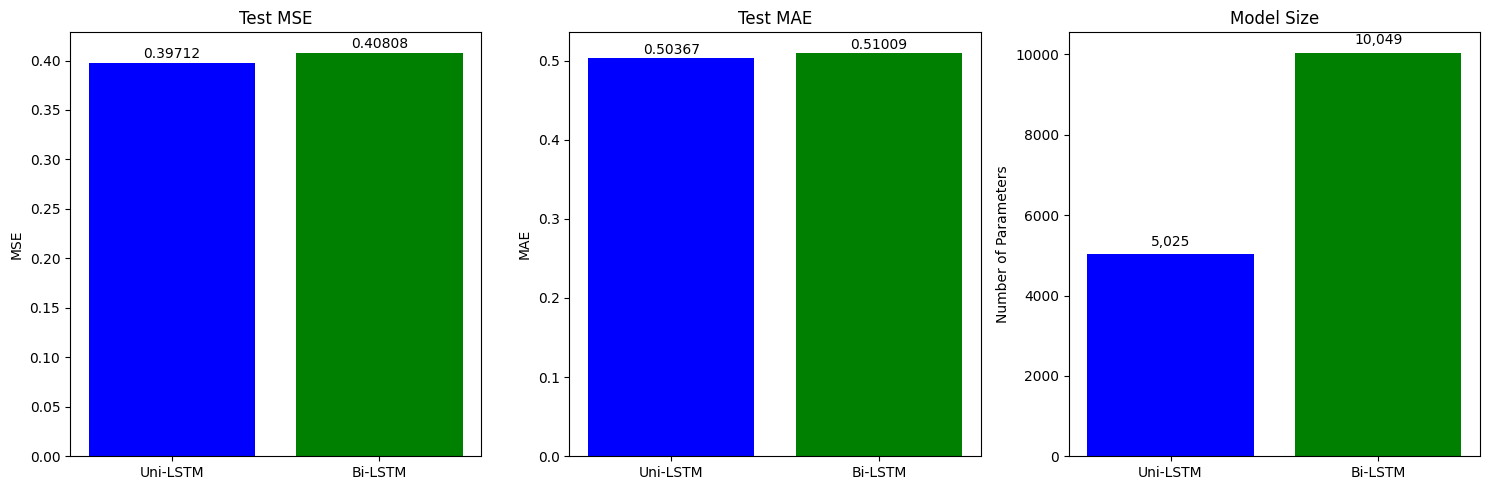

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
models = ['Uni-LSTM', 'Bi-LSTM']

# MSE
axes[0].bar(models, [mse_uni, mse_bi], color=['blue', 'green'])
axes[0].set_ylabel('MSE')
axes[0].set_title('Test MSE')
for i, v in enumerate([mse_uni, mse_bi]):
    axes[0].text(i, v + 0.005, f'{v:.5f}', ha='center')

# MAE
axes[1].bar(models, [mae_uni, mae_bi], color=['blue', 'green'])
axes[1].set_ylabel('MAE')
axes[1].set_title('Test MAE')
for i, v in enumerate([mae_uni, mae_bi]):
    axes[1].text(i, v + 0.005, f'{v:.5f}', ha='center')

# Parameters
axes[2].bar(models, [params_uni, params_bi], color=['blue', 'green'])
axes[2].set_ylabel('Number of Parameters')
axes[2].set_title('Model Size')
for i, v in enumerate([params_uni, params_bi]):
    axes[2].text(i, v + 200, f'{v:,}', ha='center')

plt.tight_layout()
plt.show()
save_figure(fig, 'bidirectional_comparison_chart')



7-2- کدام مدل MSE کمتری دارد؟ آیا تفاوت معنادار است؟ (با توجه به انحراف معیار اجراهای مکرر نیز می‌توانید قضاوت کنید.)

7-3- با توجه به اینکه در پیش‌بینی گام بعد، در زمان اجرا به داده‌های آینده دسترسی نداریم، آیا استفاده از معماری دوطرفه در این مسئله از نظر مفهومی منطقی است؟ توضیح دهید.

7-4- اگر معماری دوطرفه عملکرد بهتری نشان دهد، آیا این به معنی آن است که می‌توان در عمل از آن استفاده کرد؟ چرا؟ (به تفاوت بین مرحله آموزش و مرحله استنتاج توجه کنید.)

7-5- معماری‌های دوطرفه معمولاً در کدام دسته از مسائل کاربرد دارند و چرا در پیش‌بینی سری‌های زمانی معمولاً از آنها استفاده نمی‌شود؟

In [ ]:
print("EXTRA: Sequence Length Sensitivity (5, 20, 50, 100)")
print("="*70)

seq_lengths_extra = [5, 20, 50, 100]
results_seq = []

for sl in seq_lengths_extra:
    print(f"\n--- Seq Length = {sl} ---")
    train_loader_sl, test_loader_sl, _ = get_dataloaders(
        seq_length=sl, batch_size=batch_size, data_path=data_path
    )
    # Uni
    model_u = UniLSTM(input_size=5, hidden_size=hidden_size)
    mse_u, _, _ = train_and_evaluate(model_u, train_loader_sl, test_loader_sl, epochs=epochs, lr=learning_rate, verbose=False)
    # Bi
    model_b = BiLSTM(input_size=5, hidden_size=hidden_size)
    mse_b, _, _ = train_and_evaluate(model_b, train_loader_sl, test_loader_sl, epochs=epochs, lr=learning_rate, verbose=False)
    results_seq.append({
        'Seq Length': sl,
        'Uni MSE': mse_u,
        'Bi MSE': mse_b,
        'Bi Improvement (%)': ((mse_u - mse_b) / mse_u) * 100 if mse_u > 0 else 0
    })


In [ ]:

df_seq = pd.DataFrame(results_seq)
print("\n" + df_seq.to_string(index=False))
save_table(df_seq, 'bidirectional_seq_length_sensitivity')

# Plot seq length sensitivity
plt.figure(figsize=(10, 6))
plt.plot(df_seq['Seq Length'], df_seq['Uni MSE'], 'bo-', label='Unidirectional')
plt.plot(df_seq['Seq Length'], df_seq['Bi MSE'], 'rs-', label='Bidirectional')
plt.xlabel('Sequence Length')
plt.ylabel('Test MSE')
plt.title('Bidirectional vs Unidirectional: Effect of Sequence Length')
plt.legend()
plt.grid(True, alpha=0.3)
save_figure(plt.gcf(), 'bidirectional_seq_length')
plt.show()
